In [1]:
# Display dataset information
df.info()

# Display basic statistical details
print(df.describe())

NameError: name 'df' is not defined

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\mukesh\Downloads\train.csv")

print(df.head(10))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

In [5]:
df.info()

print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.5

In [6]:
# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with the most common value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Check missing values in each column
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [8]:
# Convert Sex into numbers
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Convert Embarked into separate 0/1 columns
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

# Display the first 5 rows
print(df.head())

KeyError: "None of [Index(['Embarked'], dtype='str')] are in the [columns]"

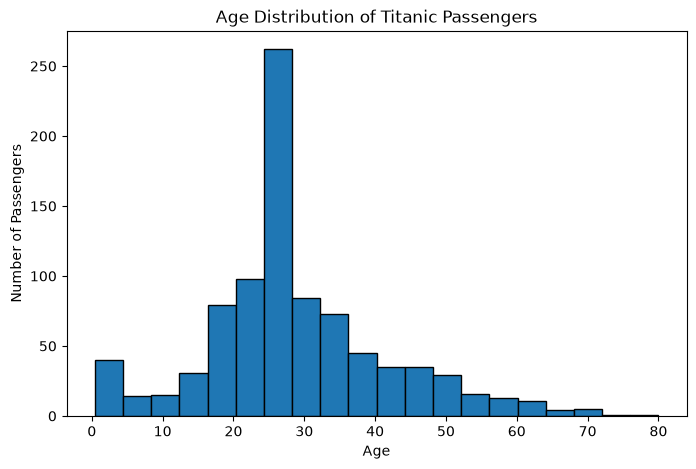

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [10]:
# Remove the Cabin column
df = df.drop(columns=["Cabin"])

# Check missing values
print(df.isnull().sum())

# Count total missing values
print("Total missing values:", df.isnull().sum().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex            891
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked_C       0
Embarked_Q       0
Embarked_S       0
dtype: int64
Total missing values: 891


In [11]:
# Save the cleaned dataset
df.to_csv("titanic_cleaned.csv", index=False)

print("Dataset saved successfully!")

# Verify the saved file
import os
print("File exists:", os.path.exists("titanic_cleaned.csv"))
print("Dataset shape:", df.shape)

Dataset saved successfully!
File exists: True
Dataset shape: (891, 13)


In [12]:
from sklearn.model_selection import train_test_split

# Select input features
X = df[["Pclass", "Sex", "Age", "Fare"]]

# Select the target we want to predict
y = df["Survived"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

# Predict survival on test data
y_pred = model.predict(X_test)

# Check model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [14]:
# Fill missing values in the input features
X = df[["Pclass", "Sex", "Age", "Fare"]].copy()

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

# Target: survival
y = df["Survived"]

# Check for missing values
print(X.isnull().sum())


Pclass      0
Sex       891
Age         0
Fare        0
dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create fresh input features
X = df[["Pclass", "Sex", "Age", "Fare"]].copy()

# Replace missing values
X = X.fillna(X.median())

# Select the target
y = df["Survived"]

# Split the updated data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Confirm no missing values remain
print("Missing values:", X_train.isnull().sum().sum())

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Missing values: 712


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [18]:
# Check which columns contain missing values
print(X.isnull().sum())

# Fill missing values using each column's median
for column in X.columns:
    X[column] = X[column].fillna(X[column].median())

# Check again
print("\nMissing values after cleaning:")
print(X.isnull().sum())

Pclass      0
Sex       891
Age         0
Fare        0
dtype: int64

Missing values after cleaning:
Pclass      0
Sex       891
Age         0
Fare        0
dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Missing values in training data:", X_train.isnull().sum().sum())

Missing values in training data: 712


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Recreate the input data
X = df[["Pclass", "Sex", "Age", "Fare"]].copy()
y = df["Survived"].copy()

# Convert input columns to numeric values
X = X.apply(pd.to_numeric, errors="coerce")

# Fill missing values using each column's median
X = X.fillna(X.median())

# Keep only rows with complete input data
X = X.dropna()
y = y.loc[X.index]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Missing values:", X_train.isnull().sum().sum())

# Train and evaluate
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [22]:
import pandas as pd

# Reload the original dataset
df = pd.read_csv(r"C:\Users\mukesh\Downloads\train.csv")

# Select features and target
X = df[["Pclass", "Sex", "Age", "Fare"]].copy()
y = df["Survived"].copy()

# Convert Sex to numeric values
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

# Fill missing values
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

# Check the data
print("Number of rows:", len(X))
print("\nMissing values:")
print(X.isnull().sum())
print("\nTarget values:")
print(y.value_counts())

Number of rows: 891

Missing values:
Pclass    0
Sex       0
Age       0
Fare      0
dtype: int64

Target values:
Survived
0    549
1    342
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.45 %


In [25]:
import pandas as pd

# Details of a new passenger
new_passenger = pd.DataFrame({
    "Pclass": [3],
    "Sex": [0],       # 0 = male, 1 = female
    "Age": [25],
    "Fare": [10.0]
})

# Predict survival
prediction = model.predict(new_passenger)

if prediction[0] == 1:
    print("Prediction: The passenger may have survived.")
else:
    print("Prediction: The passenger may not have survived.")

Prediction: The passenger may not have survived.


In [26]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[90 15]
 [20 54]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



In [27]:

import pandas as pd

# Sample house dataset
data = {
    "Area": [500, 700, 900, 1100, 1300, 1500, 1700, 1900],
    "Price": [15, 21, 27, 33, 39, 45, 51, 57]
}

house_df = pd.DataFrame(data)

print(house_df)


   Area  Price
0   500     15
1   700     21
2   900     27
3  1100     33
4  1300     39
5  1500     45
6  1700     51
7  1900     57


In [28]:

from sklearn.linear_model import LinearRegression

X_house = house_df[["Area"]]
y_house = house_df["Price"]

house_model = LinearRegression()
house_model.fit(X_house, y_house)

print("Model trained successfully!")
print("Price for a 1000 sq. ft. house:",
      house_model.predict(pd.DataFrame({"Area": [1000]}))[0],
      "lakhs")


Model trained successfully!
Price for a 1000 sq. ft. house: 30.000000000000004 lakhs


In [29]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict prices for our sample houses
y_house_pred = house_model.predict(X_house)

# Evaluate the model
mae = mean_absolute_error(y_house, y_house_pred)
mse = mean_squared_error(y_house, y_house_pred)
r2 = r2_score(y_house, y_house_pred)

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))


Mean Absolute Error: 0.0
Mean Squared Error: 0.0
R2 Score: 1.0


In [30]:
Mean Absolute Error: 0.0
Mean Squared Error: 0.0
R2 Score: 1.0

SyntaxError: invalid syntax (987529516.py, line 1)

In [31]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict prices
y_house_pred = house_model.predict(X_house)

# Calculate evaluation metrics
mae = mean_absolute_error(y_house, y_house_pred)
mse = mean_squared_error(y_house, y_house_pred)
r2 = r2_score(y_house, y_house_pred)

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))


Mean Absolute Error: 0.0
Mean Squared Error: 0.0
R2 Score: 1.0


In [32]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Split the dataset
X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(
    X_house, y_house, test_size=0.25, random_state=42
)

print("Training samples:", len(X_train_house))
print("Testing samples:", len(X_test_house))

# Train using only the training data
house_model = LinearRegression()
house_model.fit(X_train_house, y_train_house)

# Predict prices for the test data
y_test_pred = house_model.predict(X_test_house)

# Evaluate the model
print("Mean Absolute Error:", round(
    mean_absolute_error(y_test_house, y_test_pred), 2
))
print("R2 Score:", round(r2_score(y_test_house, y_test_pred), 2))


Training samples: 6
Testing samples: 2
Mean Absolute Error: 0.0
R2 Score: 1.0


In [33]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# Sample house data
house_data = pd.DataFrame({
    "Area": [500, 1000, 1500, 2000, 2500],
    "Bedrooms": [1, 2, 3, 4, 5]
})

print("Original data:")
print(house_data)

# Scale the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(house_data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=house_data.columns
)

print("\nScaled data:")
print(scaled_df.round(2))


Original data:
   Area  Bedrooms
0   500         1
1  1000         2
2  1500         3
3  2000         4
4  2500         5

Scaled data:
   Area  Bedrooms
0 -1.41     -1.41
1 -0.71     -0.71
2  0.00      0.00
3  0.71      0.71
4  1.41      1.41


In [34]:

from sklearn.preprocessing import MinMaxScaler

# Use the same sample house dataset
scaler = MinMaxScaler()

minmax_data = scaler.fit_transform(house_data)

minmax_df = pd.DataFrame(
    minmax_data,
    columns=house_data.columns
)

print("Original data:")
print(house_data)

print("\nMinMax Scaled data:")
print(minmax_df.round(2))


Original data:
   Area  Bedrooms
0   500         1
1  1000         2
2  1500         3
3  2000         4
4  2500         5

MinMax Scaled data:
   Area  Bedrooms
0  0.00      0.00
1  0.25      0.25
2  0.50      0.50
3  0.75      0.75
4  1.00      1.00


In [35]:

import pandas as pd
from sklearn.preprocessing import LabelEncoder

df_colors = pd.DataFrame({
    "Color": ["Red", "Blue", "Green", "Red", "Green", "Blue"]
})

encoder = LabelEncoder()
df_colors["Color_Encoded"] = encoder.fit_transform(df_colors["Color"])

print(df_colors)


   Color  Color_Encoded
0    Red              2
1   Blue              0
2  Green              1
3    Red              2
4  Green              1
5   Blue              0


In [36]:

df_onehot = pd.get_dummies(df_colors["Color"], dtype=int)

print("One-Hot Encoded Data:")
print(df_onehot)


One-Hot Encoded Data:
   Blue  Green  Red
0     0      0    1
1     1      0    0
2     0      1    0
3     0      0    1
4     0      1    0
5     1      0    0


In [37]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Sample house dataset
houses = pd.DataFrame({
    "Area": [600, 750, 900, 1050, 1200, 1350, 1500, 1650, 1800, 2000],
    "Price": [18, 22, 27, 31, 36, 40, 45, 49, 54, 60]
})

X = houses[["Area"]]
y = houses["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual prices:", y_test.tolist())
print("Predicted prices:", predictions.round(2).tolist())
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("R2 Score:", round(r2_score(y_test, predictions), 2))


Actual prices: [54, 22]
Predicted prices: [53.77, 22.35]
MAE: 0.29
R2 Score: 1.0


In [38]:

import joblib

# Save the trained model
joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [39]:

import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load("house_price_model.pkl")

# Predict the price of a 1400 sq. ft. house
new_house = pd.DataFrame({"Area": [1400]})

predicted_price = loaded_model.predict(new_house)

print("Predicted house price:",
      round(predicted_price[0], 2), "lakhs")


Predicted house price: 41.8 lakhs
